## **Exploratory Data Analysys (EDA)**

Dataset: Steam games Dataset 2025 (Kaggle)

**основной вопрос исследования:**
отличаются ли инди-игры от крупных проектов по уровню удовлетворенности пользователей?

## 1. загрузка данных


In [12]:
import pandas as pd
import numpy as np
from google.colab import drive


df = pd.read_csv("steam_games.csv", index_col=False)
df.head(3).T

,0,1,2
steam_appid,2719580,2719590,2719600
name,勇者の伝説の勇者,Light No Fire,Lorhaven: Cursed War
developers,['ぽけそう'],['Hello Games'],['GoldenGod Games']
publishers,['ぽけそう'],['Hello Games'],['GoldenGod Games']
categories,"['Single-player', 'Family Sharing']","['Single-player', 'Multi-player', 'Co-op', 'On...","['Single-player', 'Multi-player', 'PvP', 'Shar..."
genres,"['Casual', 'Indie']","['Action', 'Adventure']","['RPG', 'Strategy']"
required_age,0,0,0
n_achievements,0,0,32
platforms,['windows'],['windows'],"['windows', 'mac']"
is_released,True,False,True


In [13]:
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71429 entries, 0 to 71428
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   steam_appid          71429 non-null  int64  
 1   name                 71429 non-null  object 
 2   developers           71429 non-null  object 
 3   publishers           71429 non-null  object 
 4   categories           71429 non-null  object 
 5   genres               71429 non-null  object 
 6   required_age         71429 non-null  int64  
 7   n_achievements       71429 non-null  int64  
 8   platforms            71429 non-null  object 
 9   is_released          71429 non-null  bool   
 10  release_date         71429 non-null  object 
 11  additional_content   71429 non-null  object 
 12  total_reviews        71429 non-null  int64  
 13  total_positive       71429 non-null  int64  
 14  total_negative       71429 non-null  int64  
 15  review_score         71429 non-null 

,0
steam_appid,0
name,0
developers,0
publishers,0
categories,0
genres,0
required_age,0
n_achievements,0
platforms,0
is_released,0


## 2. очистка данных
для корректного анализа были сделаны:
1. **проверка на дубликаты и пропуски**
2. **фильтрация невышедших игр**: у анонсированных игр нет отзывов и цен, что искажает статистику
3. **Metacritic:** значение `0` означает, что игра не была оценена, поэтому нужно заменить `0` на `NaN`
4. для оценки качества игр берутся только проекты с больше чем с 20 отзывами, чтобы исключить ситуацию "мама разработчика оставила отзыв"
5. **генерация признаков (feature engineering):**
    * `is_indie`
    * `price_category` - ценовые диапазоны
    * `popularity_tier` - категории популярности по количеству отзывов

In [14]:
print(f"дубликатов по ID: {df.duplicated(subset=['steam_appid']).sum()}")

# только вышедшие игры
df_clean = df[df['is_released'] == True].copy()

# metacritic 0.0 -> nan
print(f"игр с оценкой 0.0 на metacritic: {df['metacritic'].value_counts()[0.0]}")
df_clean['metacritic_clean'] = df_clean['metacritic'].replace(0.0, np.nan)

# есть флаг "инди" в жанрах
df_clean['is_indie'] = df_clean['genres'].str.contains('Indie')

# ценовые категории
bins = [-1, 0, 9.99, 29.99, np.inf]
labels = ['Free', 'Budget', 'Mid-tier', 'Expensive']
df_clean['price_category'] = pd.cut(df_clean['price_initial (USD)'], bins=bins, labels=labels)

print(f"всего вышедших игр: {len(df_clean)}")

def get_popularity_tier(reviews):
    if reviews < 20:
        return 'unnoticed'
    elif reviews < 100:
        return 'noticed'
    elif reviews < 1_000:
        return 'niche'
    elif reviews < 10_000:
        return 'medium'
    elif reviews < 100_000:
        return 'hit'
    else:
        return 'superhit'

df_clean['popularity_tier'] = df_clean['total_reviews'].apply(get_popularity_tier)

# отдельный срез для анализа рейтингов
df_rated = df_clean[df_clean['total_reviews'] > 20].copy()
print(f"игр с числом отзывов > 20: {len(df_rated)}")

print(df_clean['popularity_tier'].value_counts())

дубликатов по ID: 0
игр с оценкой 0.0 на metacritic: 68906
всего вышедших игр: 58041
игр с числом отзывов > 20: 17310
popularity_tier
unnoticed    40360
noticed       9521
niche         5953
medium        1789
hit            368
superhit        50
Name: count, dtype: int64


In [15]:
def print_descriptive_stats(series, name, unit):
    n = len(series)
    mean_val = series.mean()
    median_val = series.median()
    mode_val = series.mode()[0]

    var = series.var(ddof=1)
    std = series.std(ddof=1)

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_whisker = q1 - 1.5 * iqr
    upper_whisker = q3 + 1.5 * iqr

    outliers = series[(series < lower_whisker) | (series > upper_whisker)]
    outlier_pct = (len(outliers) / n) * 100

    print(f"анализ: {name} (N = {n})")
    print(f"среднее арифметическое: {mean_val:.3f} {unit}")
    print(f"медиана: {median_val:.3f} {unit}")
    print(f"мода: {mode_val:.3f} {unit}")
    print(f"дисперсия: {var:.3f}")
    print(f"стандартное отклонение: {std:.3f} {unit}")
    print(f"квартили: Q1 = {q1:.3f}, Q3 = {q3:.3f}, IQR = {iqr:.3f}")
    print(f"границы усов boxplot: [{lower_whisker:.3f}, {upper_whisker:.3f}]")
    print(f"количество выбросов: {len(outliers)} ({outlier_pct:.2f}%)")

print_descriptive_stats(df_clean['price_initial (USD)'], "начальная цена игры", "USD")
print()
print_descriptive_stats(df_rated['positive_percentual'], "процент положительных отзывов", "%")

анализ: начальная цена игры (N = 58041)
среднее арифметическое: 8.016 USD
медиана: 4.990 USD
мода: 0.000 USD
дисперсия: 201.217
стандартное отклонение: 14.185 USD
квартили: Q1 = 0.990, Q3 = 9.990, IQR = 9.000
границы усов boxplot: [-12.510, 23.490]
количество выбросов: 3042 (5.24%)

анализ: процент положительных отзывов (N = 17310)
среднее арифметическое: 78.627 %
медиана: 82.400 %
мода: 100.000 %
дисперсия: 262.127
стандартное отклонение: 16.190 %
квартили: Q1 = 69.900, Q3 = 91.100, IQR = 21.200
границы усов boxplot: [38.100, 122.900]
количество выбросов: 432 (2.50%)


## 3. распределение целевой переменной и ключевых признаков

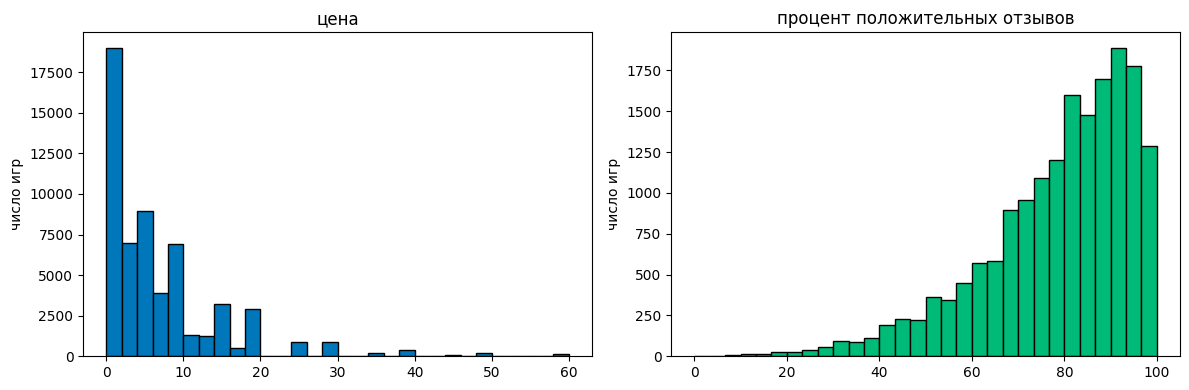

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# распределение цен < 60 чтобы усматвривалась форма
plt.subplot(1, 2, 1)
plt.hist(df_clean[df_clean['price_initial (USD)'] < 60]['price_initial (USD)'],
         bins=30, edgecolor='black', color='#07b')
plt.title('цена')
plt.ylabel('число игр')

# процент положительных отзывов
plt.subplot(1, 2, 2)
plt.hist(df_rated['positive_percentual'],
         bins=30, edgecolor='black', color='#0b7')
plt.title('процент положительных отзывов')
plt.ylabel('число игр')

plt.tight_layout()
plt.show()

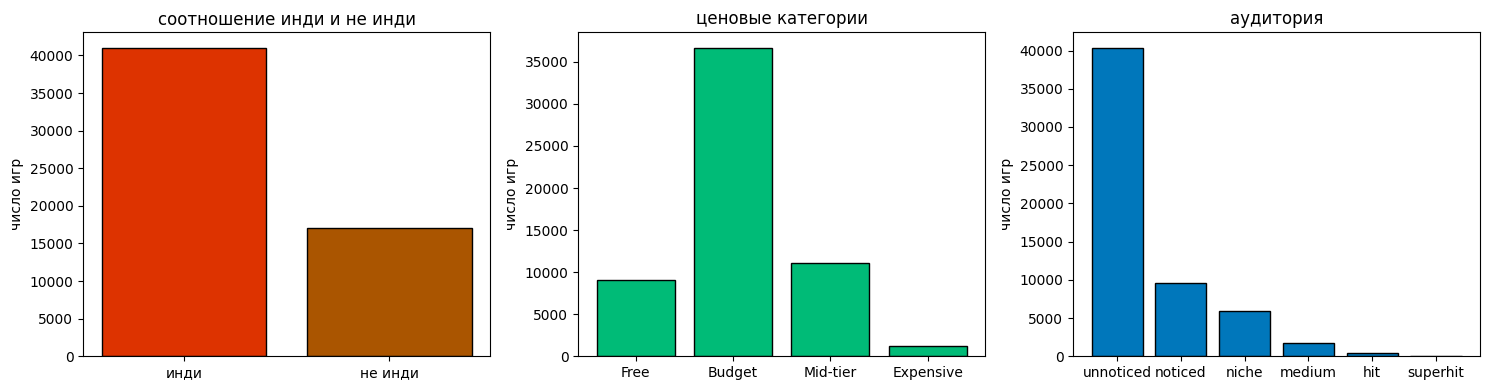

In [17]:
plt.figure(figsize=(15, 4))

# доля инди
plt.subplot(1, 3, 1)
indie_counts = df_clean['is_indie'].value_counts()
plt.bar(['инди', 'не инди'], indie_counts.values, edgecolor='black', color=["#d30", "#a50"])
plt.title('соотношение инди и не инди')
plt.ylabel('число игр')

# ценовые категории
plt.subplot(1, 3, 2)
price_order = ['Free', 'Budget', 'Mid-tier', 'Expensive']
price_counts = df_clean['price_category'].value_counts().reindex(price_order)
plt.bar(price_counts.index, price_counts.values, edgecolor='black', color='#0b7')
plt.title('ценовые категории')
plt.ylabel('число игр')

# популярность
plt.subplot(1, 3, 3)
tier_order = ['unnoticed', 'noticed', 'niche', 'medium', 'hit', 'superhit']
tier_counts = df_clean['popularity_tier'].value_counts().reindex(tier_order)
plt.bar(tier_counts.index, tier_counts.values, edgecolor='black', color='#07b')
plt.title('аудитория')
plt.ylabel('число игр')

plt.tight_layout()
plt.show()

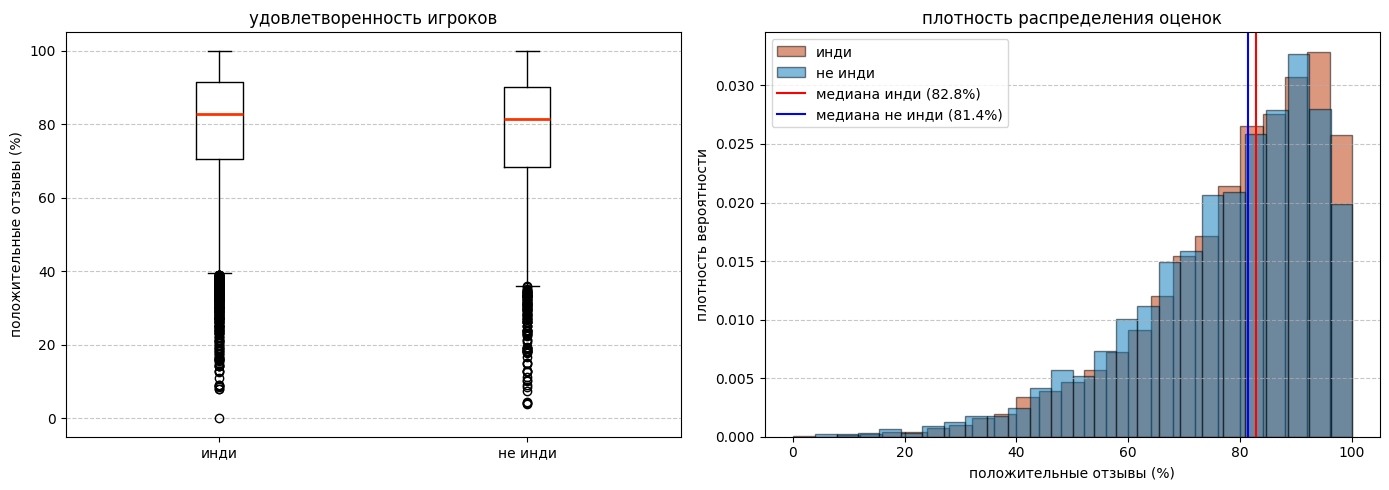

инди: медиана = 82.8%, среднее = 79.10%
не инди: медиана = 81.4%, среднее = 77.57%


In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

# boxplot
indie_ratings = df_rated[df_rated['is_indie'] == True]['positive_percentual']
non_indie_ratings = df_rated[df_rated['is_indie'] == False]['positive_percentual']

plt.boxplot([indie_ratings, non_indie_ratings],
            tick_labels=['инди', 'не инди'],
            medianprops=dict(color='#f30', linewidth=2))

plt.title('удовлетворенность игроков')
plt.ylabel('положительные отзывы (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# гистограммы
plt.subplot(1, 2, 2)

plt.hist(indie_ratings, bins=25, alpha=0.5, label='инди', color='#b30', edgecolor='black', density=True)
plt.hist(non_indie_ratings, bins=25, alpha=0.5, label='не инди', color='#07b', edgecolor='black', density=True)

plt.axvline(indie_ratings.median(), color='red', label=f'медиана инди ({indie_ratings.median()}%)')
plt.axvline(non_indie_ratings.median(), color='blue', label=f'медиана не инди ({non_indie_ratings.median():.1f}%)')

plt.title('плотность распределения оценок')
plt.xlabel('положительные отзывы (%)')
plt.ylabel('плотность вероятности')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

print(f"инди: медиана = {indie_ratings.median()}%, среднее = {indie_ratings.mean():.2f}%")
print(f"не инди: медиана = {non_indie_ratings.median()}%, среднее = {non_indie_ratings.mean():.2f}%")

## 4. Корреляционный анализ

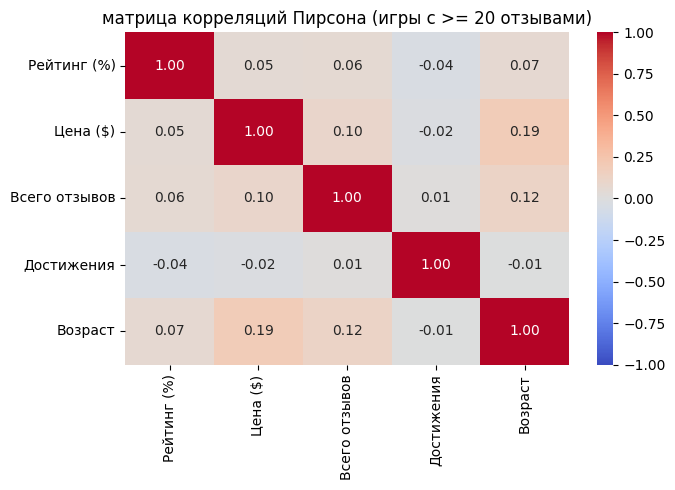

In [19]:
import seaborn as sns

# числовые признаки для анализа
corr_features = ['positive_percentual', 'price_initial (USD)', 'total_reviews', 'n_achievements', 'required_age']
feature_names = ['Рейтинг (%)', 'Цена ($)', 'Всего отзывов', 'Достижения', 'Возраст']

# расчет матриц Пирсона и Спирмена
corr_pearson = df_rated[corr_features].corr(method='pearson')
corr_spearman = df_rated[corr_features].corr(method='spearman')

corr_pearson.columns = feature_names
corr_pearson.index = feature_names

plt.figure(figsize=(7, 5))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('матрица корреляций Пирсона (игры с >= 20 отзывами)')
plt.tight_layout()
plt.show()

# сравнение Пирсона и Спирмена
corr_comparison = pd.DataFrame({
    'Пирсон (линейная)': df_rated[corr_features[1:]].corrwith(df_rated['positive_percentual'], method='pearson'),
    'Спирмен (ранговая)': df_rated[corr_features[1:]].corrwith(df_rated['positive_percentual'], method='spearman')
})
corr_comparison.index = feature_names[1:]

## 5. проверка целевой переменной на нормальность

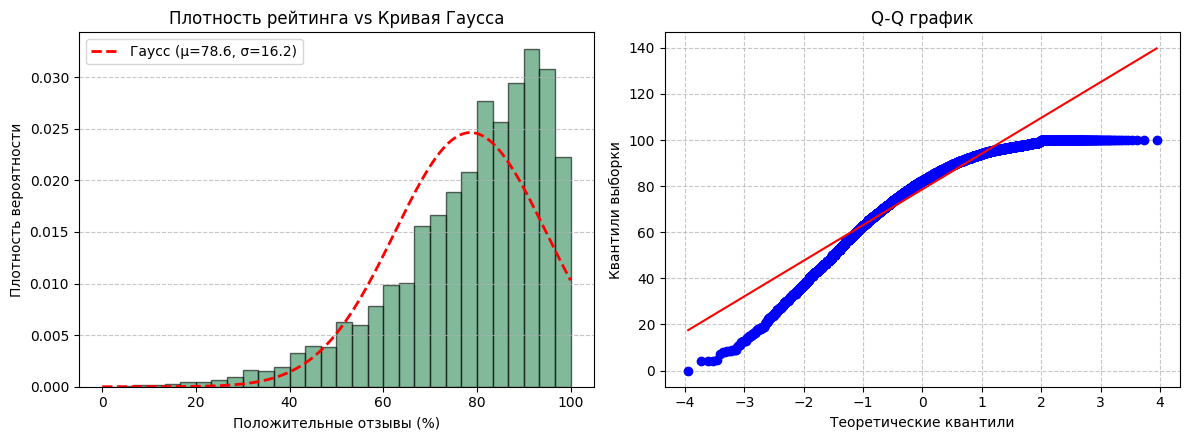

In [20]:
from scipy import stats

target_data = df_rated['positive_percentual']
mu = target_data.mean()
sigma = target_data.std(ddof=1)

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
count, bins, _ = plt.hist(target_data, bins=30, density=True, alpha=0.6, color='seagreen', edgecolor='black')
x_norm = np.linspace(bins.min(), bins.max(), 500)
y_norm = stats.norm.pdf(x_norm, loc=mu, scale=sigma)

plt.plot(x_norm, y_norm, 'r--', linewidth=2, label=f'Гаусс (μ={mu:.1f}, σ={sigma:.1f})')
plt.title('Плотность рейтинга vs Кривая Гаусса')
plt.xlabel('Положительные отзывы (%)')
plt.ylabel('Плотность вероятности')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.subplot(1, 2, 2)
stats.probplot(target_data, dist="norm", plot=plt)
plt.title('Q-Q график')
plt.xlabel('Теоретические квантили')
plt.ylabel('Квантили выборки')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# 6. проверка статистических гипотез

In [21]:
alpha = 0.05

# инди игры
group_indie = df_rated[df_rated['is_indie'] == True]['positive_percentual']

# реальные крупные
group_aaa = df_rated[(df_rated['is_indie'] == False) & (df_rated['price_initial (USD)'] >= 4.99)]['positive_percentual']

# вся остальная масса
group_non_indie_all = df_rated[df_rated['is_indie'] == False]['positive_percentual']

print(f"выборка инди: N = {len(group_indie)}")
print(f"выборка крупных проектов: N = {len(group_aaa)}")
print(f"все игры без тега Indie: N = {len(group_non_indie_all)}")
print()

# тест Манна-Уитни
u_stat, p_val_u = stats.mannwhitneyu(group_indie, group_aaa, alternative='two-sided')

# t-тест
t_stat, p_val_t = stats.ttest_ind(group_indie, group_aaa, equal_var=False)


print("сравнение: инди vs крупные проекты")
print(f"инди:     медиана = {group_indie.median():.2f}%, среднее = {group_indie.mean():.2f}%")
print(f"крупные:  медиана = {group_aaa.median():.2f}%, среднее = {group_aaa.mean():.2f}%")
print(f"Разница средних: {group_indie.mean() - group_aaa.mean():.2f}%")
print(f"Разница медиан:  {group_indie.median() - group_aaa.median():.2f}%\n")

print(f"критерий Манна-Уитни (U): статистика = {u_stat:.1f}, p-value = {p_val_u:.4e}")
print(f"t-критерий Стьюдента (t):   статистика = {t_stat:.3f}, p-value = {p_val_t:.4e}")

if p_val_u < alpha:
    print(f"результат: различия статистически значимы (p < 0.05).")
else:
    print("результат: различия статистически незначимы.")

выборка инди: N = 11979
выборка крупных проектов: N = 4482
все игры без тега Indie: N = 5331

сравнение: инди vs крупные проекты
инди:     медиана = 82.80%, среднее = 79.10%
крупные:  медиана = 81.80%, среднее = 78.04%
Разница средних: 1.06%
Разница медиан:  1.00%

критерий Манна-Уитни (U): статистика = 28084370.0, p-value = 4.9480e-06
t-критерий Стьюдента (t):   статистика = 3.772, p-value = 1.6343e-04
результат: различия статистически значимы (p < 0.05).
